# Aula 05 — Análise exploratória de dados (EDA)

A pergunta de negócio: **onde a receita está concentrada e o que explica a variação entre meses,
categorias e canais?** Antes de modelar qualquer coisa, é preciso entender a base, limpar o que
está sujo e separar sinal de ruído.

A base é **sintética e determinística** (`gerar_vendas(seed=42)`), gerada por código: nenhum dado
bruto vai para o Git e qualquer clone reproduz o mesmo resultado. A origem está em `docs/DADOS.md`.

O que precisa de teste vive em `src/opencode_harness/dados.py`; o notebook só orquestra.

## 1. Perguntas que a análise precisa responder

1. Qual é a receita total e como ela se distribui mês a mês?
2. Qual categoria e qual canal concentram a receita?
3. Existem outliers de receita? Eles distorcem a média?
4. Desconto maior derruba o ticket médio?
5. Quanta sujeira a base tem (nulos, duplicatas, devoluções) e o que fazer com ela?

## 2. Dicionário de dados

| Coluna | Tipo | Significado |
|---|---|---|
| `id` | inteiro | identificador da venda |
| `data` | data | dia da venda (2026) |
| `cliente` | texto | cliente anonimizado (`Cliente 001`...) |
| `uf` | texto | estado do cliente (pode faltar) |
| `produto` / `categoria` | texto | item vendido e sua categoria |
| `canal` | texto | `online`, `loja` (pode faltar) |
| `quantidade` | inteiro | unidades; negativo = devolução |
| `preco_unitario` | decimal | preço praticado naquela venda |
| `desconto_pct` | inteiro | desconto aplicado (0 a 20) |
| `receita` | decimal | `quantidade * preco_unitario * (1 - desconto/100)` |

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import pandas as pd

from opencode_harness import (
    gerar_vendas,
    limpar_vendas,
    outliers_iqr,
    profile,
    resumo_mensal,
    ticket_por_canal,
)

bruto = gerar_vendas(n=800, seed=42)
print("linhas:", len(bruto), "| colunas:", len(bruto.columns))
bruto.head()

linhas: 804 | colunas: 11


,id,data,cliente,uf,produto,categoria,canal,quantidade,preco_unitario,desconto_pct,receita
0,1,2026-10-29,Cliente 064,SP,licenca-office,software,online,-1,521.52,5,-495.44
1,2,2026-05-29,Cliente 079,SP,mouse,perifericos,loja,-1,86.97,0,-86.97
2,3,2026-12-24,Cliente 079,RJ,antivirus,software,loja,-1,114.01,5,-108.31
3,4,2026-09-05,Cliente 117,RJ,headset,perifericos,loja,2,332.68,0,665.36
4,5,2026-03-10,Cliente 018,NaN,notebook,hardware,online,1,3329.66,0,3329.66


## 3. Perfil e qualidade

`profile()` é o primeiro comando em qualquer base nova: tipo, nulos e cardinalidade. Nulos aqui
foram injetados de propósito para a limpeza ter o que fazer.

In [2]:
qualidade = profile(bruto)
qualidade

,dtype,nulos,nulos_pct,unicos
id,int64,0,0.00,800
data,datetime64[us],0,0.00,316
cliente,str,0,0.00,119
uf,str,20,2.49,6
produto,str,0,0.00,10
categoria,str,0,0.00,4
canal,str,8,1.00,2
quantidade,int64,0,0.00,6
preco_unitario,float64,0,0.00,792
desconto_pct,int64,0,0.00,5


## 4. Limpeza

Regras aplicadas por `limpar_vendas`:

- texto normalizado (sem espaços, minúsculo; UF em maiúsculo);
- UF/canal ausentes viram `NAO_INFORMADO` / `nao_informado` — descartar a venda perderia receita;
- duplicatas exatas removidas;
- devoluções (`quantidade <= 0`) e preço inválido fora;
- receita **recalculada**, para não confiar em coluna pronta.

In [3]:
limpo = limpar_vendas(bruto)

print(f"bruto: {len(bruto)} linhas | limpo: {len(limpo)} linhas")
print("duplicatas restantes:", int(limpo.duplicated().sum()))
print("nulos restantes:", int(limpo.isna().sum().sum()))
print("devolucoes removidas:", int((bruto["quantidade"] <= 0).sum()))

assert not limpo.duplicated().any()
assert (limpo["quantidade"] > 0).all()
assert limpo["receita"].sum() > 0
limpo.head()

bruto: 804 linhas | limpo: 797 linhas
duplicatas restantes: 0
nulos restantes: 0
devolucoes removidas: 3


,id,data,cliente,uf,produto,categoria,canal,quantidade,preco_unitario,desconto_pct,receita
0,4,2026-09-05,cliente 117,RJ,headset,perifericos,loja,2,332.68,0,665.36
1,5,2026-03-10,cliente 018,NAO_INFORMADO,notebook,hardware,online,1,3329.66,0,3329.66
2,6,2026-03-22,cliente 042,SP,curso-sql,educacao,online,3,224.73,0,674.19
3,7,2026-10-31,cliente 038,SP,licenca-office,software,loja,1,478.39,0,478.39
4,8,2026-03-26,cliente 067,SP,antivirus,software,online,1,128.65,0,128.65


## 5. Receita ao longo do ano

A base tem sazonalidade plantada (novembro e dezembro mais fortes). Em dado real, o próximo passo
seria comparar com anos anteriores antes de chamar isso de tendência.

In [4]:
mensal = resumo_mensal(limpo)
print(f"receita total: R$ {limpo['receita'].sum():,.2f}")
mensal

receita total: R$ 884,347.97


,mes,receita,vendas,unidades,ticket_medio
0,2026-01,48640.53,40,67,1216.01
1,2026-02,47977.80,45,83,1066.17
2,2026-03,78623.02,67,114,1173.48
3,2026-04,124572.43,59,98,2111.40
4,2026-05,41878.51,54,89,775.53
5,2026-06,73974.61,70,141,1056.78
6,2026-07,84430.38,72,135,1172.64
7,2026-08,40331.19,62,94,650.50
8,2026-09,64345.73,60,101,1072.43
9,2026-10,34320.89,46,73,746.11


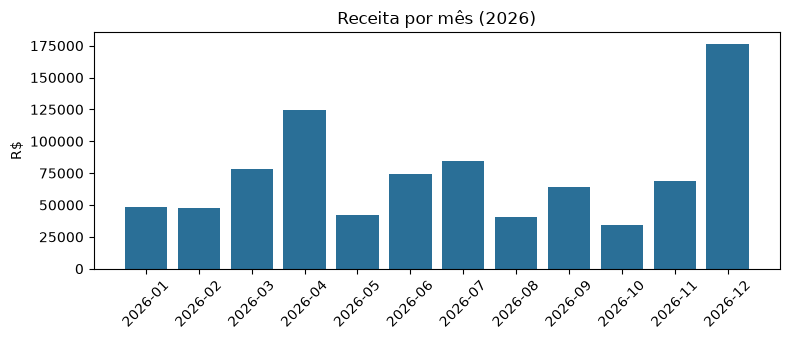

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(mensal["mes"], mensal["receita"], color="#2a6f97")
ax.set_title("Receita por mês (2026)")
ax.set_ylabel("R$")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

## 6. Categoria e canal

Receita por categoria mostra **onde** o dinheiro entra; por canal, **como** ele entra. Ticket médio
é `receita / número de vendas`, não o preço do produto.

In [6]:
por_categoria = (
    limpo.groupby("categoria", as_index=False)
    .agg(receita=("receita", "sum"), vendas=("id", "count"))
    .assign(ticket_medio=lambda d: (d["receita"] / d["vendas"]).round(2))
    .sort_values("receita", ascending=False)
)
por_categoria

,categoria,receita,vendas,ticket_medio
1,hardware,655176.22,163,4019.49
2,perifericos,119540.22,397,301.11
3,software,62578.31,140,446.99
0,educacao,47053.22,97,485.08


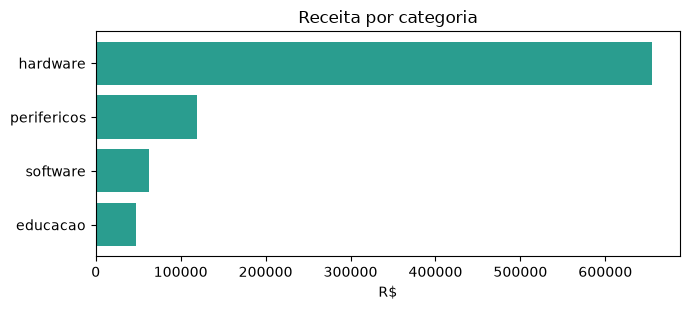

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(por_categoria["categoria"], por_categoria["receita"], color="#2a9d8f")
ax.invert_yaxis()
ax.set_title("Receita por categoria")
ax.set_xlabel("R$")
fig.tight_layout()
plt.show()

In [8]:
canais = ticket_por_canal(limpo)
canais

,canal,receita,vendas,ticket_medio
0,online,538845.57,508,1060.72
1,loja,333357.87,281,1186.33
2,nao_informado,12144.53,8,1518.07


## 7. Outliers

A regra de Tukey marca o que está a mais de 1,5 IQR da caixa. Em receita, isso captura tanto erro de
digitação quanto venda legítima de item caro — por isso outlier **não se remove no automático**:
primeiro se investiga.

In [9]:
marcados = outliers_iqr(limpo["receita"])
print(f"outliers de receita: {int(marcados.sum())} de {len(limpo)} ({marcados.mean():.1%})")
limpo.loc[marcados, ["produto", "quantidade", "preco_unitario", "receita"]].nlargest(5, "receita")

outliers de receita: 114 de 797 (14.3%)


,produto,quantidade,preco_unitario,receita
793,notebook,2,21602.22,43204.44
790,notebook,5,3461.00,17305.00
616,notebook,4,3391.59,13566.36
762,notebook,4,3258.72,13034.88
531,notebook,4,3462.93,11773.96


## 8. Desconto e ticket

Média por faixa de desconto: se o ticket não cair com desconto, ou o desconto está sendo dado em
produtos caros, ou a amostra por faixa é pequena. As duas leituras são possíveis — a tabela mostra
quantas vendas sustentam cada média.

In [10]:
desconto = (
    limpo.groupby("desconto_pct", as_index=False)
    .agg(vendas=("id", "count"), ticket=("receita", "mean"), unidades=("quantidade", "mean"))
    .round(2)
)
desconto

,desconto_pct,vendas,ticket,unidades
0,0,475,1241.72,1.72
1,5,122,867.22,1.85
2,10,93,918.10,1.80
3,15,77,1091.05,1.88
4,20,30,644.62,1.70


## 9. Conclusões

- A base tem **qualidade suficiente para modelar** depois da limpeza: sem duplicata, sem devolução e
  com nulos tratados como categoria, não como descarte.
- A receita é **concentrada em dezembro** e em poucas categorias; comparar médias sem olhar o volume
  mensal levaria a conclusão errada.
- Outliers de receita são majoritariamente **itens caros legítimos** (notebook/monitor), não erro —
  remover tudo distorceria o total.
- Desconto não mostra relação simples com ticket: é preciso controlar por produto/categoria.

**O que eu faria com mais tempo:** comparar 2026 com o ano anterior, olhar devoluções por produto e
testar se o canal `nao_informado` tem padrão (falha de integração?).

## 10. Próximos passos

1. Módulo 06: usar esta base para um **baseline de Machine Learning** (prever venda de alto valor).
2. Persistir a base limpa em `data/processed/` e carregar no SQLite da aula 04 (a pasta é gitignored).
3. Criar um dicionário de dados oficial em `docs/DADOS.md`.

In [11]:
assert len(mensal) == 12
assert mensal["receita"].sum() == round(limpo["receita"].sum(), 2)
assert por_categoria["receita"].sum() == round(limpo["receita"].sum(), 2)
assert (limpo["receita"] > 0).all()
assert not limpo.duplicated().any()
print("EDA OK")

EDA OK
